# Hospital operations dashboard: the three views, rebuilt in Python

**RECONSTRUCTION, on SYNTHETIC data.** The capstone delivered a Power BI report with three views:
appointment counts, physician workload, and patient geographic distribution. The `.pbix` file and
the clinic's sample data did not survive. What did survive is the schema
(`../original/dump-Hospital-202512151315.sql`, 13 tables, no rows).

This notebook rebuilds each view as a chart so the logic can be inspected and run anywhere:

- `generate_synthetic_data.py` makes clearly fake rows (SSNs in the never-issued 900 series,
  555-01xx phones, "City, ST" addresses).
- `build_sqlite.py` translates the MySQL dump to SQLite, loads the rows with foreign keys enforced,
  and runs the SQL in `../reconstruction/queries/`.
- Every number below is synthetic. The shapes are designed to be plausible, not to describe any
  real clinic.

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

import build_sqlite as hospital

conn = hospital.build()   # builds hospital.sqlite from the dump + synthetic CSVs on first run
QUERIES = Path("../reconstruction/queries")

def run(name: str) -> pd.DataFrame:
    return pd.read_sql_query((QUERIES / name).read_text(), conn)

# Chart styling shared by every figure: one blue for data, one orange for a fitted line
# or reference mark, quiet grid, no top/right spines.
C = {"blue": "#2a78d6", "orange": "#eb6834", "text": "#0b0b0b", "muted": "#52514e",
     "grid": "#e6e5e1", "surface": "#fcfcfb"}
plt.rcParams.update({
    "figure.facecolor": C["surface"], "axes.facecolor": C["surface"], "savefig.facecolor": C["surface"],
    "axes.edgecolor": C["grid"], "axes.grid": True, "grid.color": C["grid"], "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False,
    "text.color": C["text"], "axes.labelcolor": C["muted"], "axes.titlecolor": C["text"],
    "xtick.color": C["muted"], "ytick.color": C["muted"], "font.size": 11, "figure.dpi": 110,
})
money = lambda v, _: f"${v/1000:,.0f}k"

## View 1: appointment counts

**Dashboard question:** how busy is the clinic, month by month and department by department?

**Query:** `01_appointments_by_month.sql` groups `Appointment` by the month of `Starto`.
`02_appointments_by_department.sql` joins through `Affiliated_With` (primary affiliation only, so a
physician in two departments is counted once) to `Department`.

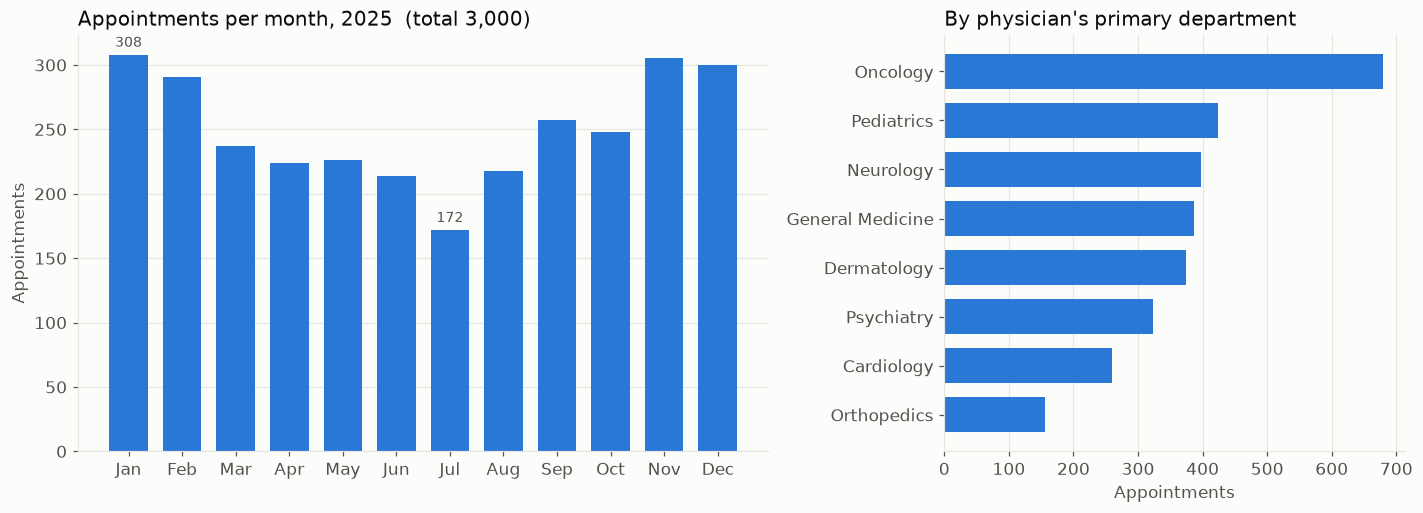

,department,appointments,distinct_patients,physicians,appointments_per_physician
0,Oncology,679,328,10,67.9
1,Pediatrics,424,257,5,84.8
2,Neurology,397,241,5,79.4
3,General Medicine,386,253,4,96.5
4,Dermatology,375,245,4,93.8
5,Psychiatry,323,214,5,64.6
6,Cardiology,260,192,4,65.0
7,Orthopedics,156,133,3,52.0


In [2]:
monthly = run("01_appointments_by_month.sql")
by_dept = run("02_appointments_by_department.sql")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [3, 2]})

labels = pd.to_datetime(monthly.month).dt.strftime("%b")
ax1.bar(labels, monthly.appointments, color=C["blue"], width=0.72)
for i in (monthly.appointments.idxmax(), monthly.appointments.idxmin()):
    ax1.annotate(f"{monthly.appointments[i]:,}", (i, monthly.appointments[i]), ha="center", va="bottom",
                 xytext=(0, 3), textcoords="offset points", color=C["muted"], fontsize=9)
ax1.grid(axis="x", visible=False)
ax1.set_ylabel("Appointments")
ax1.set_title(f"Appointments per month, 2025  (total {monthly.appointments.sum():,})", loc="left")

dept = by_dept.iloc[::-1]
ax2.barh(dept.department, dept.appointments, color=C["blue"], height=0.72)
ax2.grid(axis="y", visible=False)
ax2.set_xlabel("Appointments")
ax2.set_title("By physician's primary department", loc="left")

fig.tight_layout()
fig.savefig("../docs/view1_appointments.png", dpi=130, bbox_inches="tight")
plt.show()
by_dept

## View 2: physician workload

**Dashboard question:** who is carrying the load, and is it spread evenly?

**Query:** `03_physician_workload.sql`. One row per physician from `Physician`, left-joined to
`Appointment` for visit counts and hours, with correlated subqueries for prescriptions
(`Prescribes`), procedures (`Undergoes`) and primary-care panel size (`Patient.PCP`). Subqueries
rather than more joins so the appointment rows do not multiply the other counts.

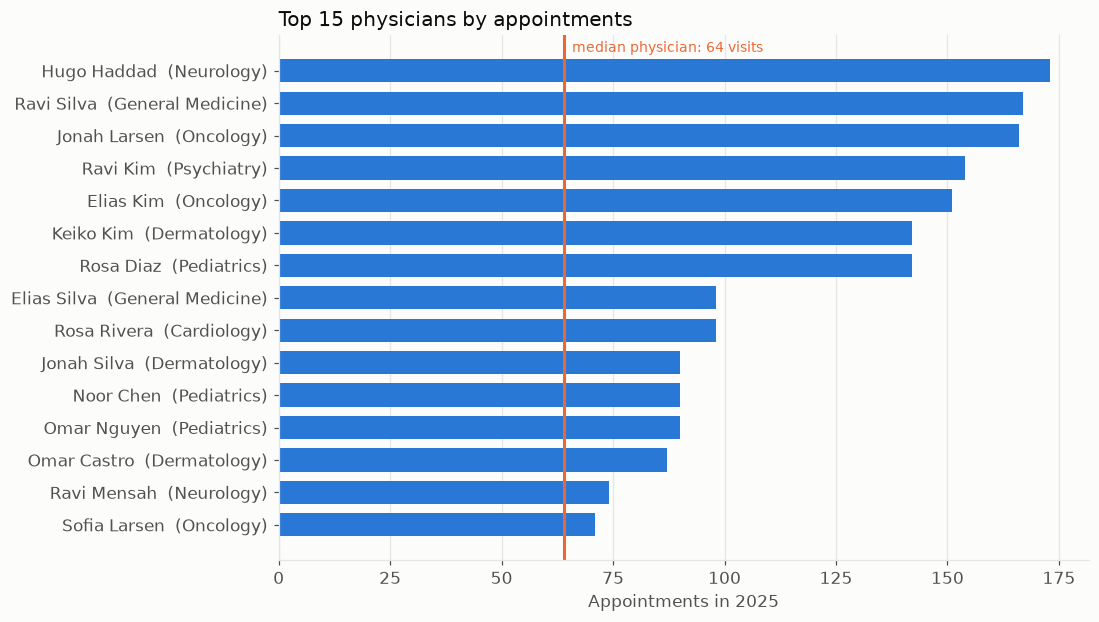

,EmployeeID,physician,Position,primary_department,appointments,appointment_hours,distinct_patients,prescriptions,procedures_performed,primary_care_panel
0,24,Hugo Haddad,Resident,Neurology,173,110.2,143,137,9,5
1,17,Ravi Silva,Staff Physician,General Medicine,167,104.9,132,106,0,14
2,2,Jonah Larsen,Attending Physician,Oncology,166,102.9,136,97,7,9
3,6,Ravi Kim,Staff Physician,Psychiatry,154,96.6,120,116,7,12
4,13,Elias Kim,Senior Attending,Oncology,151,95.6,128,110,8,13
5,34,Keiko Kim,Senior Attending,Dermatology,142,90.1,116,89,5,7
6,30,Rosa Diaz,Resident,Pediatrics,142,89.0,120,103,12,13
7,28,Elias Silva,Senior Attending,General Medicine,98,64.1,87,73,10,17
8,12,Rosa Rivera,Attending Physician,Cardiology,98,58.2,84,73,4,6
9,25,Jonah Silva,Resident,Dermatology,90,57.3,83,66,7,7


In [3]:
workload = run("03_physician_workload.sql")
top = workload.head(15).iloc[::-1]
median = workload.appointments.median()

fig, ax = plt.subplots(figsize=(9.5, 6.2))
ax.barh(top.physician + "  (" + top.primary_department.fillna("no department") + ")", top.appointments,
        color=C["blue"], height=0.72)
ax.axvline(median, color=C["orange"], linewidth=2)
ax.text(median, len(top) - 0.3, f"  median physician: {median:.0f} visits", color=C["orange"], fontsize=9, va="center")
ax.grid(axis="y", visible=False)
ax.set_xlabel("Appointments in 2025")
ax.set_title("Top 15 physicians by appointments", loc="left")
fig.savefig("../docs/view2_physician_workload.png", dpi=130, bbox_inches="tight")
plt.show()
workload.head(10)

## View 3: patient geographic distribution

**Dashboard question:** where do patients come from, and which departments are they attached to?

**Query:** `04_patient_distribution.sql` splits `Patient.Address` ("City, ST") and counts patients
and their appointments per city. `05_patients_by_primary_care_department.sql` follows
`Patient.PCP` to the physician's primary department. In Power BI the city table fed a map visual;
here it is a bar chart because the synthetic addresses have no coordinates.

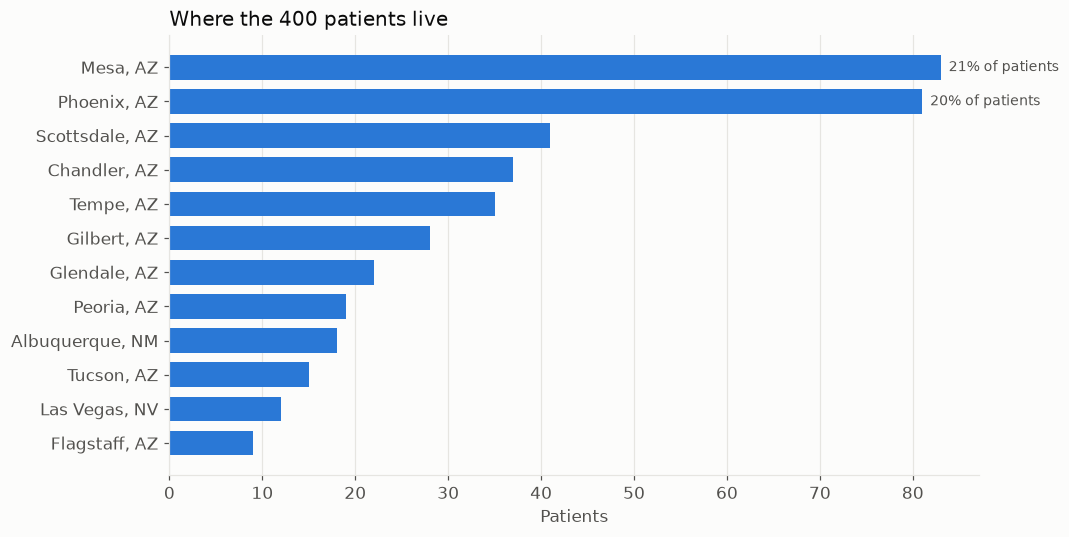

,pcp_department,patients,pcps_in_department,avg_panel_size
0,Oncology,103,10,10.3
1,Psychiatry,57,5,11.4
2,Pediatrics,46,5,9.2
3,General Medicine,46,4,11.5
4,Neurology,41,5,8.2
5,Cardiology,38,4,9.5
6,Orthopedics,35,3,11.7
7,Dermatology,34,4,8.5


In [4]:
geo = run("04_patient_distribution.sql")
by_pcp_dept = run("05_patients_by_primary_care_department.sql")

rows = geo.iloc[::-1]
fig, ax = plt.subplots(figsize=(9.5, 5.2))
ax.barh(rows.city + ", " + rows.state, rows.patients, color=C["blue"], height=0.72)
for _, r in geo.head(2).iterrows():
    ax.text(r.patients, geo.index.max() - r.name, f"  {r.pct_of_patients:.0f}% of patients", va="center", color=C["muted"], fontsize=9)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Patients")
ax.set_title(f"Where the {geo.patients.sum():,} patients live", loc="left")
fig.savefig("../docs/view3_patient_distribution.png", dpi=130, bbox_inches="tight")
plt.show()
by_pcp_dept

## How this maps back to the Power BI report

From the project proposal and the resume description, the report had:

| Power BI element | Fed by | Here |
|---|---|---|
| Cards: total appointments, active physicians, patients | aggregates of `Appointment`, `Physician`, `Patient` | totals in the titles above |
| Column chart: appointments by month | `01_appointments_by_month.sql` | View 1, left |
| Bar chart: appointments by department | `02_appointments_by_department.sql` | View 1, right |
| Table / bar: physician activity | `03_physician_workload.sql` | View 2 |
| Map: patients by city | `04_patient_distribution.sql` | View 3 (bars, no coordinates in synthetic data) |
| Slicers: month, department | `WHERE` clauses on the same queries | filter the DataFrames |

If the original `.pbix` or screenshots are recovered they go in `../original/` and this notebook stays
as the reproducible version of the same logic.

In [5]:
conn.close()